# Deep learning: frozen embeddings and fine-tuned DistilBERT (notebook 03)

Session 7 order: first freeze a pretrained encoder and train only a small head on its
embeddings (cheap, cached), then fine-tune the whole encoder (expensive). Both are
compared with the classical models of notebook 02 on the same five splits, scored once
on test per (model, seed). Heavy cells need a GPU and the `torch`, `transformers` and
`sentence-transformers` packages; without a GPU or those packages the run cells are skipped and the
notebook only reads saved results from `outputs/deep/`.

Run time: roughly one hour on one GPU for all seeds (an estimate, not measured); under a
minute when it only reads saved results.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_curve

from modules import data_helper as dh
from modules import features as ft
from modules import eval_helper as ev
from modules import results_helper as rh
from modules import deep_runs as dr

DATA = "../data/fake_job_postings.csv"

In [2]:
SEED = 0
SEEDS = [0, 1, 2, 3, 4]
BERT_SEEDS = [0]  # pilot first: read the seconds per epoch below, then set it to SEEDS
SPLIT_PATH = "splits/seed0.npz"
OUT_CLASSICAL = "outputs/classical"
OUT_DEEP = "outputs/deep"
GROUPS = ["classical", "deep"]

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
BERT_MODEL = "distilbert-base-uncased"
EPOCHS, BATCH_SIZE, MAX_LEN, LR = 3, 16, 256, 2e-5

# Heavy cells run only where the libraries exist AND a GPU is visible (never on a laptop CPU);
# the heads only need the cached embeddings.
HAVE_TORCH = all(importlib.util.find_spec(m) for m in ("torch", "transformers", "sentence_transformers"))
HAVE_GPU = HAVE_TORCH and __import__("torch").cuda.is_available()
HAVE_EMBEDDINGS = os.path.exists("features/" + EMBED_MODEL.replace("/", "_") + "_emb.npy")
RUN_EMBED, RUN_BERT = HAVE_GPU, HAVE_GPU
RUN_HEADS = HAVE_GPU or HAVE_EMBEDDINGS
print({"torch stack": HAVE_TORCH, "gpu": HAVE_GPU, "cached embeddings": HAVE_EMBEDDINGS})

dh.seed_everything(SEED)
sns.set_theme(style="whitegrid")

{'torch stack': False, 'gpu': False, 'cached embeddings': False}


## Data and splits

The same cleaned frame and the same saved splits as the classical notebook, so every model
is scored on identical rows.

In [3]:
df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
print("rows:", len(df), "| fraud:", int(df["fraudulent"].sum()))

rows: 17599 | fraud: 856


## Step 1: frozen sentence embeddings

`all-MiniLM-L6-v2` turns each ad (the joined `text` column) into one 384-dimensional vector.
Nothing is trained here. The vectors are cached in `features/` keyed by `job_id`, so this
cell is a no-op the second time.

In [4]:
if RUN_EMBED:
    device = dr.resolve_device("auto")
    dr.print_run_info(device, BATCH_SIZE, MAX_LEN)
    dr.run_embed(df, device, EMBED_MODEL)
else:
    print("skipped: needs a GPU and torch + sentence-transformers")

skipped: needs a GPU and torch + sentence-transformers


## Step 2: sklearn heads on the frozen embeddings

A logistic regression (C picked on validation PR-AUC) and a small MLP, trained on the cached
vectors with CPU only. Each is run for all five seeds; the threshold is picked on validation and
the test rows are scored once.

In [5]:
if RUN_HEADS:
    dr.run_heads(df, SEEDS, OUT_DEEP, EMBED_MODEL)
else:
    print("skipped: no cached embeddings here")

skipped: no cached embeddings here


## Step 3: fine-tune DistilBERT

The whole encoder is trained with a linear classification layer on top: AdamW, learning rate
2e-5 with warm-up and linear decay, square-root class weights in the loss, bf16 autocast on
CUDA, and early stopping on validation PR-AUC (the best epoch's weights are restored). Texts
are truncated to 256 tokens. `BERT_SEEDS` starts as one seed so the epoch time can be read
before committing to all five.

In [6]:
if RUN_BERT:
    dr.run_bert(df, BERT_SEEDS, OUT_DEEP, device, BERT_MODEL, epochs=EPOCHS,
                batch_size=BATCH_SIZE, max_len=MAX_LEN, lr=LR)
else:
    print("skipped: needs a GPU and torch + transformers")

skipped: needs a GPU and torch + transformers


## Training curves of the fine-tuned model

Session 7: read the curve, not only the end number. Per epoch validation PR-AUC and training
loss, from the `history` stored with each saved run.

In [7]:
import glob, json
rows = []
for path in sorted(glob.glob(os.path.join(OUT_DEEP, "bert_*_seed*.json"))):
    with open(path, encoding="utf-8") as f:
        rec = json.load(f)
    for h in rec.get("history", []):
        rows.append({"seed": rec["seed"], **h})
hist = pd.DataFrame(rows)
if hist.empty:
    print("no fine-tuning history found yet")
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for seed, g in hist.groupby("seed"):
        axes[0].plot(g["epoch"], g["val_pr_auc"], marker="o", label=f"seed {seed}")
        axes[1].plot(g["epoch"], g["train_loss"], marker="o", label=f"seed {seed}")
    axes[0].set_title("Validation PR-AUC per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("PR-AUC")
    axes[1].set_title("Training loss per epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("weighted cross-entropy")
    axes[0].legend()
    plt.show()
    print("seconds per epoch:", hist["seconds"].round(0).tolist())

no fine-tuning history found yet


# Final comparison: classical and deep models together

The remaining sections read the saved files of every model found in `outputs/classical/` and
`outputs/deep/`. Nothing is fitted below.

In [8]:
OUT_DEEP = "outputs/deep"
DIRS = {"classical": OUT_CLASSICAL, "deep": OUT_DEEP}


class StopExecution(Exception):
    """Stops the notebook quietly when there is nothing to report."""

    def _render_traceback_(self):
        pass  # IPython hook: an empty traceback, so the notebook just stops

## Load the saved results

`results_helper.load_results` collects one row per (model, seed) from the JSON
files of the groups listed in `GROUPS` (deep results only when `outputs/deep/` is non-empty). If
nothing is found we stop here with a message instead of crashing.

In [9]:
dirs = [d for g, d in DIRS.items() if g in GROUPS and os.path.isdir(d) and os.listdir(d)]
res = rh.load_results(*dirs) if dirs else pd.DataFrame(columns=["group"])
res = res[res["group"].isin(GROUPS)]
if res.empty:
    print("No result files were found. Looked in:", dirs)
    print("Run the experiment cells of this notebook first, then re-run this section.")
    raise StopExecution
print(f"{len(res)} runs found: {res['model'].nunique()} models, "
      f"seeds {sorted(int(x) for x in res['seed'].unique())}")

30 runs found: 6 models, seeds [0, 1, 2, 3, 4]


## Which runs were found

Each cell counts finished runs; a full grid has exactly one run per (model, seed).

In [10]:
res.groupby(["model", "seed"]).size().unstack(fill_value=0)

seed,0,1,2,3,4
model,,,,,
dummy_majority,1,1,1,1,1
dummy_stratified,1,1,1,1,1
logreg,1,1,1,1,1
logreg_bm25,1,1,1,1,1
mlp,1,1,1,1,1
tree,1,1,1,1,1


## Headline test metrics

Mean and standard deviation over seeds, sorted by mean test PR-AUC. The dummy rows
are the floor every real model has to beat. With a single seed there is no standard
deviation and only the mean is shown.

In [11]:
def fmt(col):
    """mean +- std over seeds for one metric; a lone seed has no std."""
    g = res.groupby("model")[col]
    return [f"{m:.3f} +- {s:.3f}" if pd.notna(s) else f"{m:.3f}"
            for m, s in zip(g.mean(), g.std())]

order = res.groupby("model")["test_pr_auc"].mean().sort_values(ascending=False).index
pd.DataFrame({
    "seeds": res.groupby("model").size(),
    "test PR-AUC": fmt("test_pr_auc"),
    "test F1": fmt("test_f1"),
    "test precision": fmt("test_precision"),
    "test recall": fmt("test_recall"),
}).loc[order]

,seeds,test PR-AUC,test F1,test precision,test recall
model,,,,,
logreg_bm25,5,0.847 +- 0.073,0.804 +- 0.055,0.856 +- 0.034,0.760 +- 0.081
mlp,5,0.846 +- 0.077,0.787 +- 0.081,0.863 +- 0.051,0.726 +- 0.106
logreg,5,0.821 +- 0.063,0.772 +- 0.042,0.827 +- 0.052,0.726 +- 0.053
tree,5,0.402 +- 0.066,0.501 +- 0.055,0.434 +- 0.054,0.634 +- 0.165
dummy_stratified,5,0.049 +- 0.001,0.093 +- 0.000,0.049 +- 0.000,1.000 +- 0.000
dummy_majority,5,0.049 +- 0.000,0.093 +- 0.000,0.049 +- 0.000,1.000 +- 0.000


Why the two dummy rows show recall 1.0: a constant score has a single possible threshold,
and picking it by F1 flags every ad as fraud. Their precision therefore equals the
share of fraud in the data, which is the floor every real model has to beat.

## Validation vs test PR-AUC

Validation is what models, hyper-parameters and thresholds were chosen on; test is
the honest number. The difference is the price of that selection.

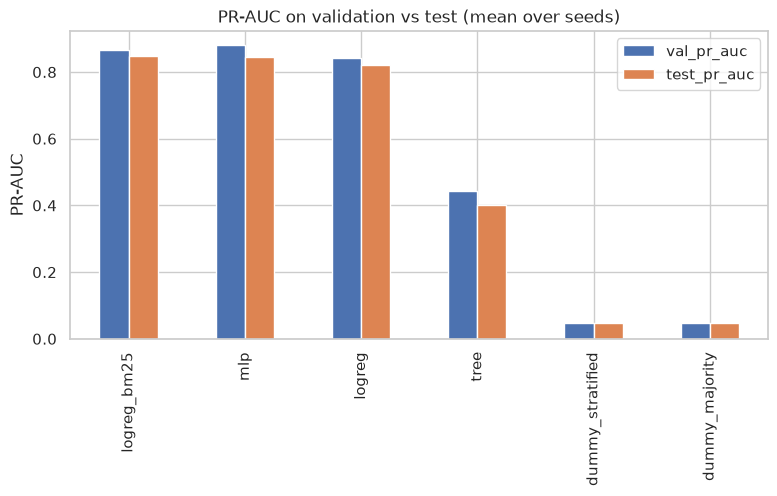

In [12]:
means = res.groupby("model")[["val_pr_auc", "test_pr_auc"]].mean().loc[order]
ax = means.plot(kind="bar", figsize=(9, 4))
ax.set_title("PR-AUC on validation vs test (mean over seeds)")
ax.set_xlabel("")
ax.set_ylabel("PR-AUC")
plt.show()

Reading: each model has two bars, validation and test, on the same 0 to 1 scale;
the validation bar tends to sit at or above the test bar.

## Generalisation gap

Train PR-AUC minus test PR-AUC per model (mean over seeds). A large gap means the
model memorised its training rows.

In [13]:
g = res.groupby("model").agg(train_pr_auc=("train_pr_auc", "mean"),
                             test_pr_auc=("test_pr_auc", "mean"))
g["gap (train - test)"] = g["train_pr_auc"] - g["test_pr_auc"]
g.sort_values("gap (train - test)", ascending=False)

,train_pr_auc,test_pr_auc,gap (train - test)
model,,,
tree,0.638283,0.402411,0.235873
logreg,0.991778,0.820640,0.171139
logreg_bm25,1.000000,0.847136,0.152864
mlp,0.992673,0.846210,0.146463
dummy_majority,0.048679,0.048580,0.000099
dummy_stratified,0.048816,0.048734,0.000082


## Per-seed spread

Session 7 rule of thumb: a model that wins by less than its own standard deviation
has not won. Each point is one split seed.

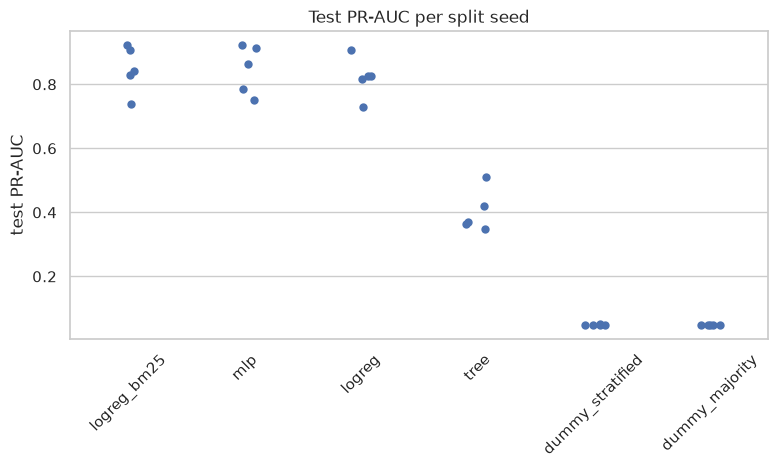

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(data=res, x="model", y="test_pr_auc", order=order, ax=ax, size=6)
ax.set_title("Test PR-AUC per split seed")
ax.set_xlabel("")
ax.set_ylabel("test PR-AUC")
ax.tick_params(axis="x", rotation=45)
plt.show()

Reading: every point is one seed of one model; models whose point clouds overlap
are indistinguishable at this level of noise.

## Seed 0 in detail

The NPZ files hold y and scores for validation and test in the same row order as the
split, so curves and matrices can be rebuilt without refitting anything. If no
seed-0 run exists we stop with a message.

In [15]:
seed0 = res[res["seed"] == 0]
if seed0.empty:
    print("No seed-0 runs found; the remaining sections need seed 0.")
    raise StopExecution
seed_runs = {row["model"]: (rh.load_scores(DIRS[row["group"]], row["model"], 0), row["thr"])
             for _, row in seed0.iterrows()}
y_test = next(iter(seed_runs.values()))[0]["y_test"]
print("seed-0 models:", ", ".join(seed_runs))

seed-0 models: dummy_majority, dummy_stratified, logreg_bm25, logreg, mlp, tree


### Precision-recall curves on the test split (seed 0)

Built from the saved scores with sklearn's `precision_recall_curve`; the dashed line
is the fraud base rate, i.e. what random guessing scores.

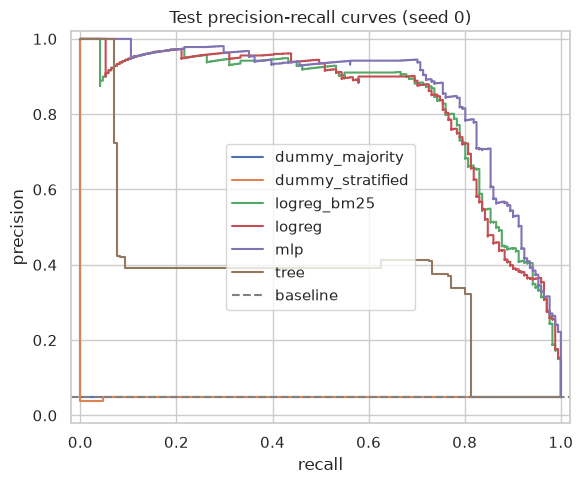

In [16]:
curves = {name: precision_recall_curve(y_test, s["score_test"])[:2]
          for name, (s, thr) in seed_runs.items()}
pos_rate = float(y_test.mean())
ev.plot_pr_curves(curves, pos_rate=pos_rate,
                  title="Test precision-recall curves (seed 0)")
plt.show()

Reading: the x axis is recall, the y axis precision; closer to the top-right corner
is better, and the dashed grey line is the base rate every curve should beat.

### Confusion matrices at the validation-chosen threshold (seed 0)

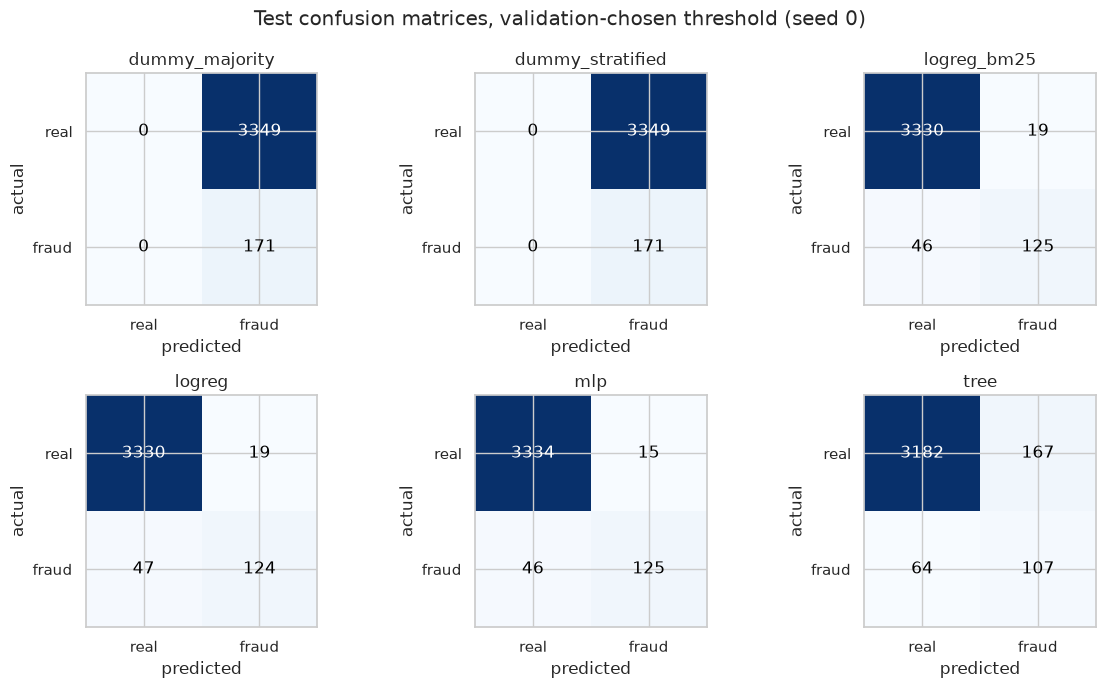

In [17]:
cms = {}
for name, (s, thr) in seed_runs.items():
    pred = (s["score_test"] >= thr).astype(int)
    cms[name] = confusion_matrix(y_test, pred)
ev.plot_confusions(cms, ["real", "fraud"],
                   title="Test confusion matrices, validation-chosen threshold (seed 0)")
plt.show()

Reading: rows are the actual class, columns the predicted class; the diagonal holds
the correct calls.

## Fit time per model

Wall-clock seconds per run (mean over seeds and slowest seed), as recorded by the
runners.

In [18]:
res.groupby("model")["seconds"].agg(["mean", "max"]).sort_values("mean").round(1)

,mean,max
model,,
dummy_majority,0.0,0.0
dummy_stratified,0.0,0.0
logreg,60.8,70.3
logreg_bm25,78.6,80.0
tree,88.6,91.0
mlp,439.7,483.1


## Which frauds does each model catch? (seed 0)

At each model's own validation-chosen threshold: how many of the test frauds does
model A catch that model B misses. Plus the frauds caught by at least one model but
not by all.

In [19]:
fraud_idx = np.where(y_test == 1)[0]
# The dummies are left out: at their threshold they flag every ad, so they "catch" every fraud.
caught = {name: frozenset(fraud_idx[s["score_test"][fraud_idx] >= thr])
          for name, (s, thr) in seed_runs.items() if not name.startswith("dummy")}
names = list(caught)
overlap = pd.DataFrame(0, index=names, columns=names)
for a in names:
    for b in names:
        overlap.loc[a, b] = len(caught[a] - caught[b])
union = set().union(*caught.values())
inter = set(fraud_idx)
for c in caught.values():
    inter &= c
print("test frauds caught by at least one model but not by all:", len(union - inter))
overlap

test frauds caught by at least one model but not by all: 51


,logreg_bm25,logreg,mlp,tree
logreg_bm25,0,1,4,31
logreg,0,0,3,31
mlp,4,4,0,34
tree,13,14,16,0


Reading: cell (A, B) counts test frauds caught by A but missed by B, so the
diagonal is zero by construction; rows with large values catch much that the column
models let through.

## The ads nobody catches (seed 0)

The last Session 6 step: read the test frauds that no model flagged at its own
threshold. These are the target for the next iteration. This cell needs the seed-0
split file to look the rows up.

In [20]:
if not os.path.exists(SPLIT_PATH):
    print("splits/seed0.npz not found; cannot look up the missed ads.")
else:
    df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
    test = df.iloc[dh.load_splits(SPLIT_PATH, df)["test"]]
    caught_any = np.zeros(len(test), dtype=bool)
    for name, (s, thr) in seed_runs.items():
        if not name.startswith("dummy"):      # dummies flag every ad, so they would hide all misses
            caught_any |= (s["score_test"] >= thr)
    missed = test[(y_test == 1) & ~caught_any]
    print(len(missed), "test frauds that no model caught:")
    for _, r in missed.iterrows():
        print("-", str(r["title"])[:80], "|", str(r["description"])[:150], "\n")

30 test frauds that no model caught:
- Financing Auto(car) sales | If you have experience in financing for auto sales and a great attitude you can work in our Hazelcrest office.  From $500 top $1000 a week by contract 

-  JOB VACANCIES AT MONTCALM LUXURY HOTEL LONDON. | Montcalm Luxury Hotel London34-40 Great Cumberland Pl Marble Arch, London W1H 7TW, United KingdomTelephone: #PHONE_12f88d70e2cf3375f39a78f81729c0e76eb 

- Urgent Requirement For The Position Technical Lead - Rhomobile Technical Mobilit | 1.    Technical Lead - Rhomobile Technical Mobility Lead Developer  NOTES-  In case if Rhomobile is difficult to find, Please find people with experti 

- Customer Assistant | Every project we deal with involves many different specialists. Their talent and knowledge, skills and enthusiasm help us to find the solution even in 

- software development life cycle |   Title: Service Desk ResourceLocation: Atlanta, GADuration: Long Term Position Description: The position of Senior Software 

## Findings (deep models)

To be written after the full deep runs have been read; the numbers in the tables above are
the source of truth until then.